# Customer Churn Analysis & Prediction
**End-to-end machine learning project | E-commerce customer dataset**

This notebook performs data quality checks, cleaning, exploratory data analysis (EDA), feature engineering and selection, imbalance handling, model comparison and tuning, evaluation, interpretation of churn drivers, and actionable retention recommendations.

**Target:** `Churned` (1 = churned, 0 = retained).  
**Dataset:** 50,000 customer records supplied with this project.  
**Reproducibility:** fixed random seed; stratified train/test split; preprocessing is fitted only on training data to avoid leakage.

In [1]:
# If running locally, keep `ecommerce_customer_churn_dataset.csv` beside this notebook.
# Install any missing packages with: pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = "ecommerce_customer_churn_dataset.csv"
df_raw = pd.read_csv(DATA_PATH)
print("Dataset loaded:", df_raw.shape)
display(df_raw.head())

Dataset loaded: (50000, 25)


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,2.0,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,9.2,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,11.5,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,15.0,147.33,47.0,44.10,5.4,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,32.5,141.30,73.0,25.20,5.5,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


## 1. Initial data audit

Check shape, column types, target balance, duplicate records, missing values, and descriptive statistics before changing the data.

In [2]:
print("Rows, columns:", df_raw.shape)
print("\nData types:")
display(df_raw.dtypes.rename("dtype").to_frame())
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("\nTarget counts:")
display(df_raw["Churned"].value_counts(dropna=False).rename_axis("Churned").to_frame("count"))
print("\nTarget proportions:")
display((df_raw["Churned"].value_counts(normalize=True).sort_index()*100).round(2).rename("percent").to_frame())
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean()*100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing[missing["missing_count"] > 0])
display(df_raw.describe(include="all").T)

Rows, columns: (50000, 25)

Data types:


,dtype
Age,float64
Gender,object
Country,object
City,object
Membership_Years,float64
Login_Frequency,float64
Session_Duration_Avg,float64
Pages_Per_Session,float64
Cart_Abandonment_Rate,float64
Wishlist_Items,float64



Duplicate rows: 0

Target counts:


,count
Churned,
0,35550
1,14450



Target proportions:


,percent
Churned,
0,71.1
1,28.9


,missing_count,missing_percent
Social_Media_Engagement_Score,6000,12.00
Credit_Balance,5500,11.00
Mobile_App_Usage,5000,10.00
Returns_Rate,4491,8.98
Wishlist_Items,4000,8.00
Product_Reviews_Written,3500,7.00
Discount_Usage_Rate,3500,7.00
Session_Duration_Avg,3399,6.80
Pages_Per_Session,3000,6.00
Days_Since_Last_Purchase,3000,6.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,47505.0,NaN,NaN,NaN,37.802968,11.834668,5.0,29.0,38.0,46.0,200.0
Gender,50000,3,Female,25116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,50000,8,USA,17384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,50000,40,Houston,3549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Membership_Years,50000.0,NaN,NaN,NaN,2.984009,2.059105,0.1,1.4,2.5,4.0,10.0
Login_Frequency,50000.0,NaN,NaN,NaN,11.62466,7.810657,0.0,6.0,11.0,17.0,46.0
Session_Duration_Avg,46601.0,NaN,NaN,NaN,27.660754,10.871013,1.0,19.7,26.8,34.7,75.6
Pages_Per_Session,47000.0,NaN,NaN,NaN,8.737811,3.77822,1.0,6.0,8.4,11.2,24.1
Cart_Abandonment_Rate,50000.0,NaN,NaN,NaN,57.079973,16.282723,0.0,46.4,58.1,68.7,143.74335
Wishlist_Items,46000.0,NaN,NaN,NaN,4.298391,3.189754,0.0,2.0,4.0,6.0,28.0


## 2. Data cleaning

- Remove exact duplicate rows.
- Validate the target and remove rows where the target is missing (if any).
- Convert numeric-looking fields to numeric values where possible.
- Keep missing feature values for imputation inside the modelling pipeline, so imputers learn from training data only.
- Inspect implausible values. Since this is a synthetic-style e-commerce dataset and no authoritative business limits were supplied, flag extremes rather than silently deleting valid-looking records.

In [3]:
df = df_raw.copy()
before = len(df)
df = df.drop_duplicates()
duplicates_removed = before - len(df)

# Target must be known and binary for supervised classification.
df = df[df["Churned"].notna()].copy()
df["Churned"] = pd.to_numeric(df["Churned"], errors="coerce")
df = df[df["Churned"].isin([0, 1])].copy()
df["Churned"] = df["Churned"].astype(int)

# Trim whitespace in categorical columns and normalize empty strings to missing.
cat_cols_initial = df.select_dtypes(include=["object", "category"]).columns.tolist()
for col in cat_cols_initial:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Convert all non-target, non-categorical columns to numeric when appropriate.
for col in df.columns:
    if col not in cat_cols_initial and col != "Churned":
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Exact duplicate rows removed: {duplicates_removed}")
print("Cleaned shape:", df.shape)
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Target labels:", sorted(df["Churned"].unique()))

Exact duplicate rows removed: 0
Cleaned shape: (50000, 25)
Remaining missing values: 49081
Target labels: [np.int64(0), np.int64(1)]


### Missingness and potential outliers

Missing values are handled later by median imputation for numerical features and most-frequent imputation for categorical features. The plots below help identify skew and unusually high/low values. Outliers are not automatically removed because they may represent real high-value or at-risk customers.

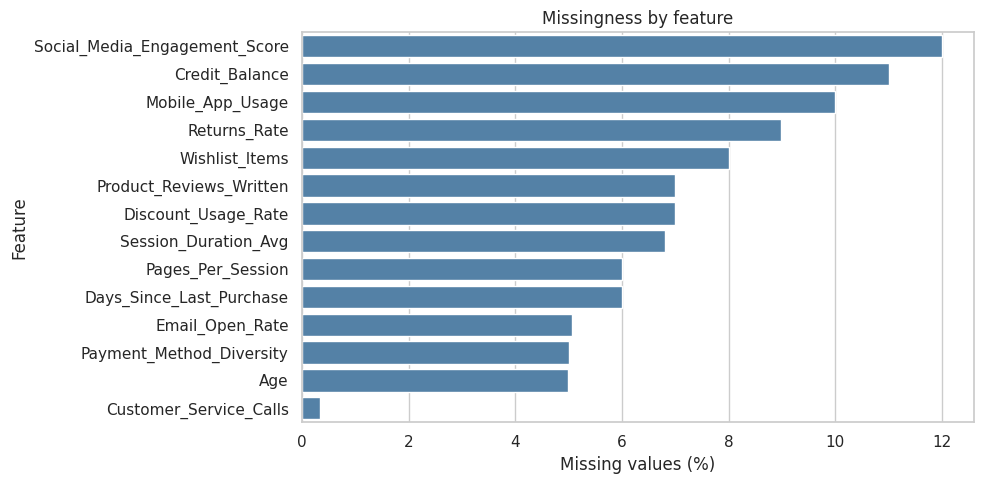

,0.00,0.01,0.25,0.50,0.75,0.99,1.00
Age,5.00,18.00,29.00,38.00,46.00,66.00,200.00
Membership_Years,0.10,0.20,1.40,2.50,4.00,10.00,10.00
Login_Frequency,0.00,0.00,6.00,11.00,17.00,32.00,46.00
Session_Duration_Avg,1.00,6.50,19.70,26.80,34.70,55.30,75.60
Pages_Per_Session,1.00,1.20,6.00,8.40,11.20,18.30,24.10
Cart_Abandonment_Rate,0.00,16.50,46.40,58.10,68.70,90.80,143.74
Wishlist_Items,0.00,0.00,2.00,4.00,6.00,14.00,28.00
Total_Purchases,-13.00,2.00,8.00,12.00,17.00,31.20,128.70
Average_Order_Value,26.38,45.29,87.05,112.97,144.44,252.30,9666.38
Days_Since_Last_Purchase,0.00,0.00,9.00,21.00,41.00,137.00,287.00


In [4]:
missing_plot = (df.isna().mean()*100).sort_values(ascending=False)
missing_plot = missing_plot[missing_plot > 0]
plt.figure(figsize=(10, 5))
if len(missing_plot):
    sns.barplot(x=missing_plot.values, y=missing_plot.index, color="steelblue")
    plt.xlabel("Missing values (%)"); plt.ylabel("Feature")
    plt.title("Missingness by feature")
else:
    plt.text(0.5, 0.5, "No missing values", ha="center", va="center")
plt.tight_layout(); plt.show()

numeric_for_eda = df.select_dtypes(include=np.number).columns.drop("Churned", errors="ignore").tolist()
display(df[numeric_for_eda].quantile([0, .01, .25, .5, .75, .99, 1]).T.round(2))

## 3. Exploratory data analysis (EDA)

Explore the overall churn rate, numeric feature distributions, churn differences across key numerical variables, and categorical churn rates. These are associations, not proof of causation.

Overall churn rate: 28.90%


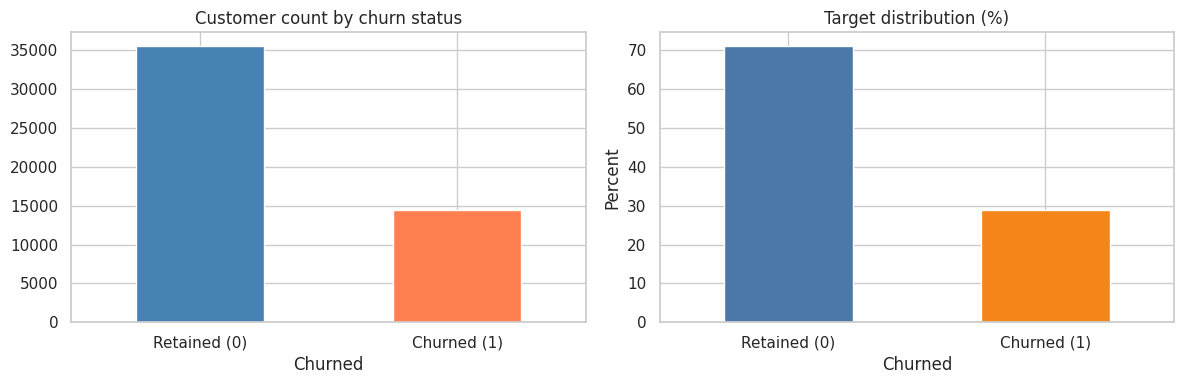

In [5]:
churn_rate = df["Churned"].mean()
print(f"Overall churn rate: {churn_rate:.2%}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Churned"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["steelblue", "coral"])
axes[0].set_title("Customer count by churn status")
axes[0].set_xticklabels(["Retained (0)", "Churned (1)"], rotation=0)
(df["Churned"].value_counts(normalize=True).sort_index()*100).plot(
    kind="bar", ax=axes[1], color=["#4C78A8", "#F58518"])
axes[1].set_title("Target distribution (%)"); axes[1].set_ylabel("Percent")
axes[1].set_xticklabels(["Retained (0)", "Churned (1)"], rotation=0)
plt.tight_layout(); plt.show()

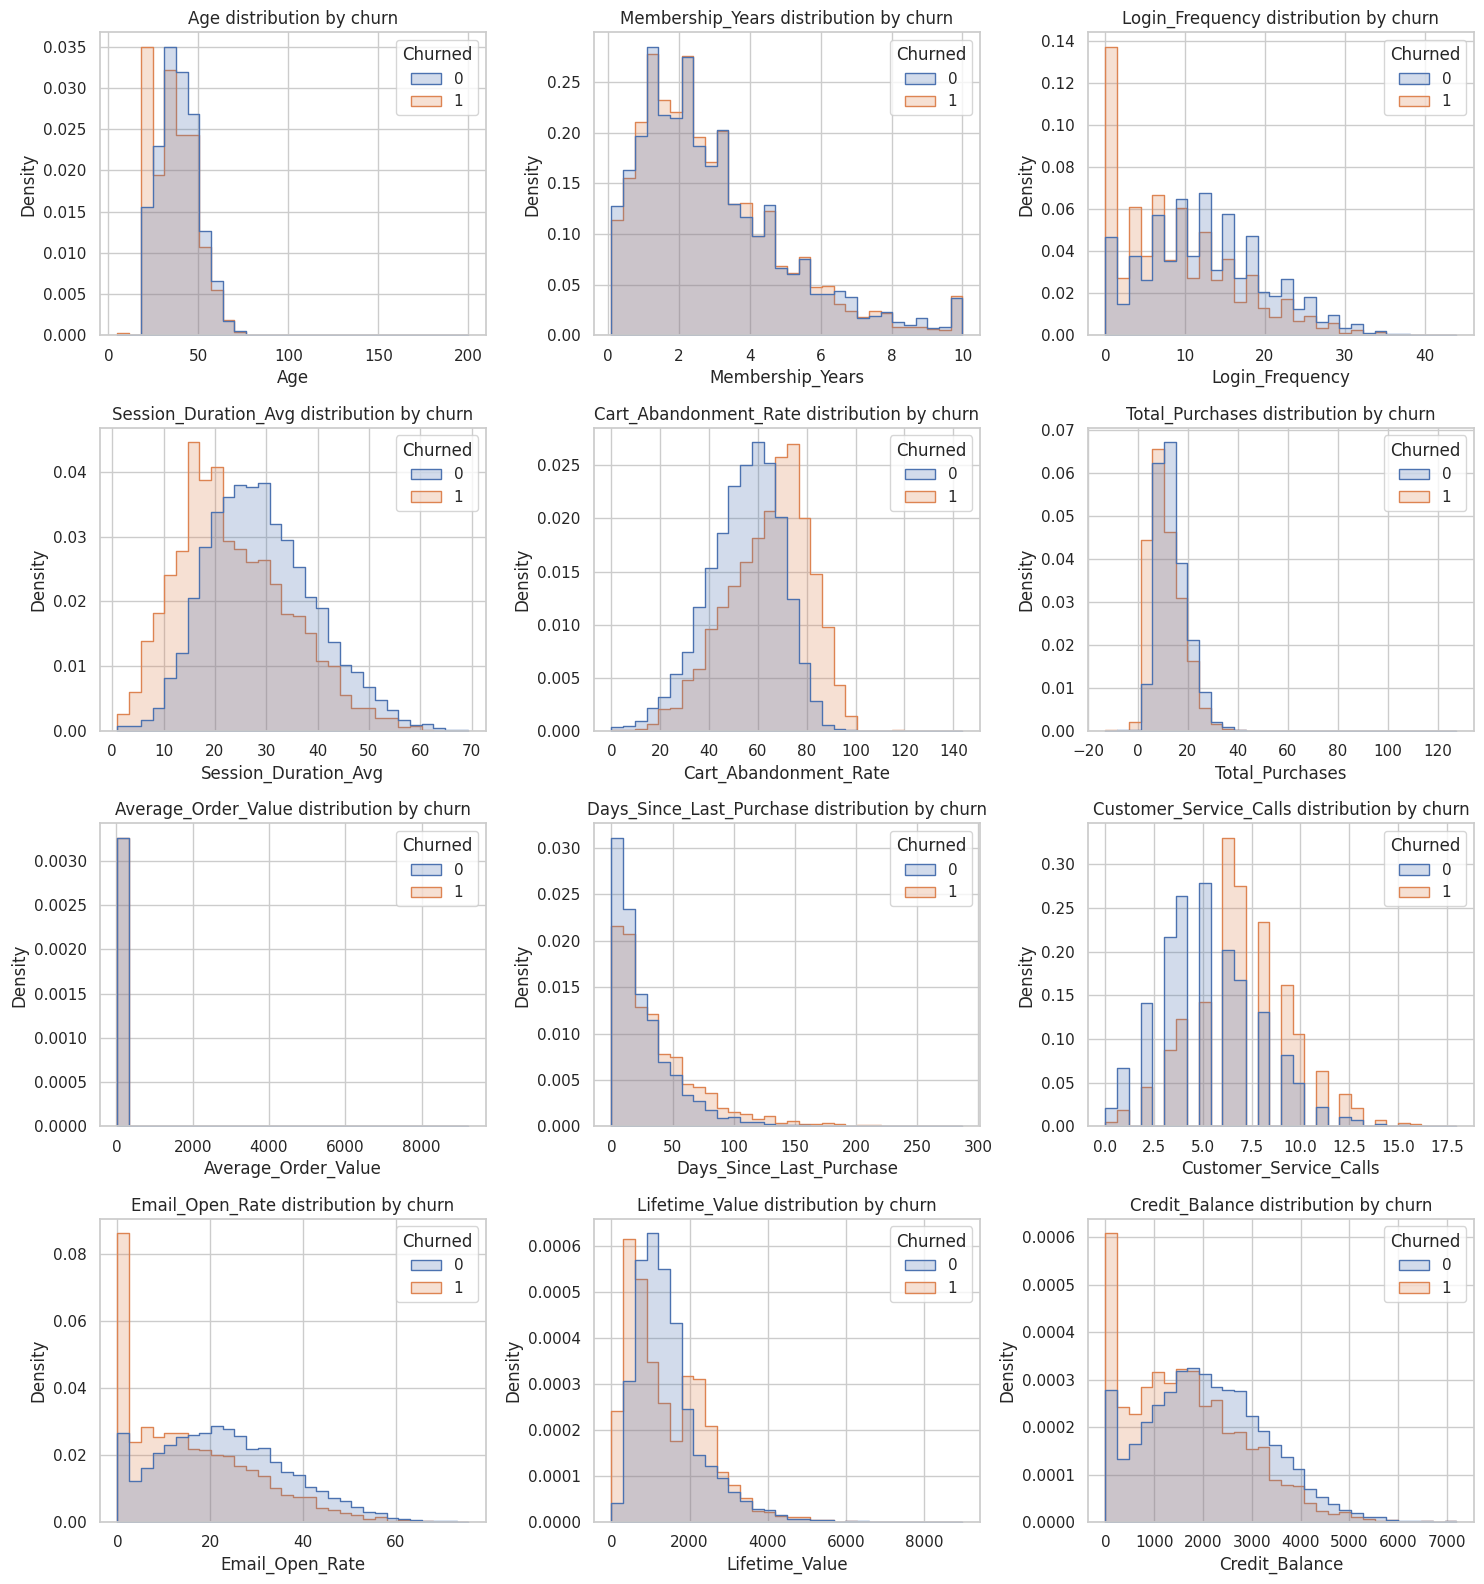

In [6]:
# Numeric distribution overview (sample features to keep plots readable)
eda_num = [c for c in [
    "Age", "Membership_Years", "Login_Frequency", "Session_Duration_Avg",
    "Cart_Abandonment_Rate", "Total_Purchases", "Average_Order_Value",
    "Days_Since_Last_Purchase", "Customer_Service_Calls", "Email_Open_Rate",
    "Lifetime_Value", "Credit_Balance"
] if c in df.columns]
ncols = 3
nrows = int(np.ceil(len(eda_num)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4*nrows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, eda_num):
    sns.histplot(data=df.sample(min(12000, len(df)), random_state=RANDOM_STATE), x=col, hue="Churned", bins=30, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_title(f"{col} distribution by churn")
for ax in axes[len(eda_num):]:
    ax.remove()
plt.tight_layout(); plt.show()

,Retained_median,Churned_median,difference_churn_minus_retained
Credit_Balance,2028.000,1558.000,-470.00
Lifetime_Value,1266.790,1132.730,-134.06
Average_Order_Value,108.935,124.395,15.46
Cart_Abandonment_Rate,55.500,66.600,11.10
Social_Media_Engagement_Score,30.500,19.900,-10.60
Email_Open_Rate,21.900,13.400,-8.50
Days_Since_Last_Purchase,19.000,26.000,7.00
Session_Duration_Avg,28.200,22.000,-6.20
Mobile_App_Usage,20.000,14.700,-5.30
Discount_Usage_Rate,41.600,36.400,-5.20


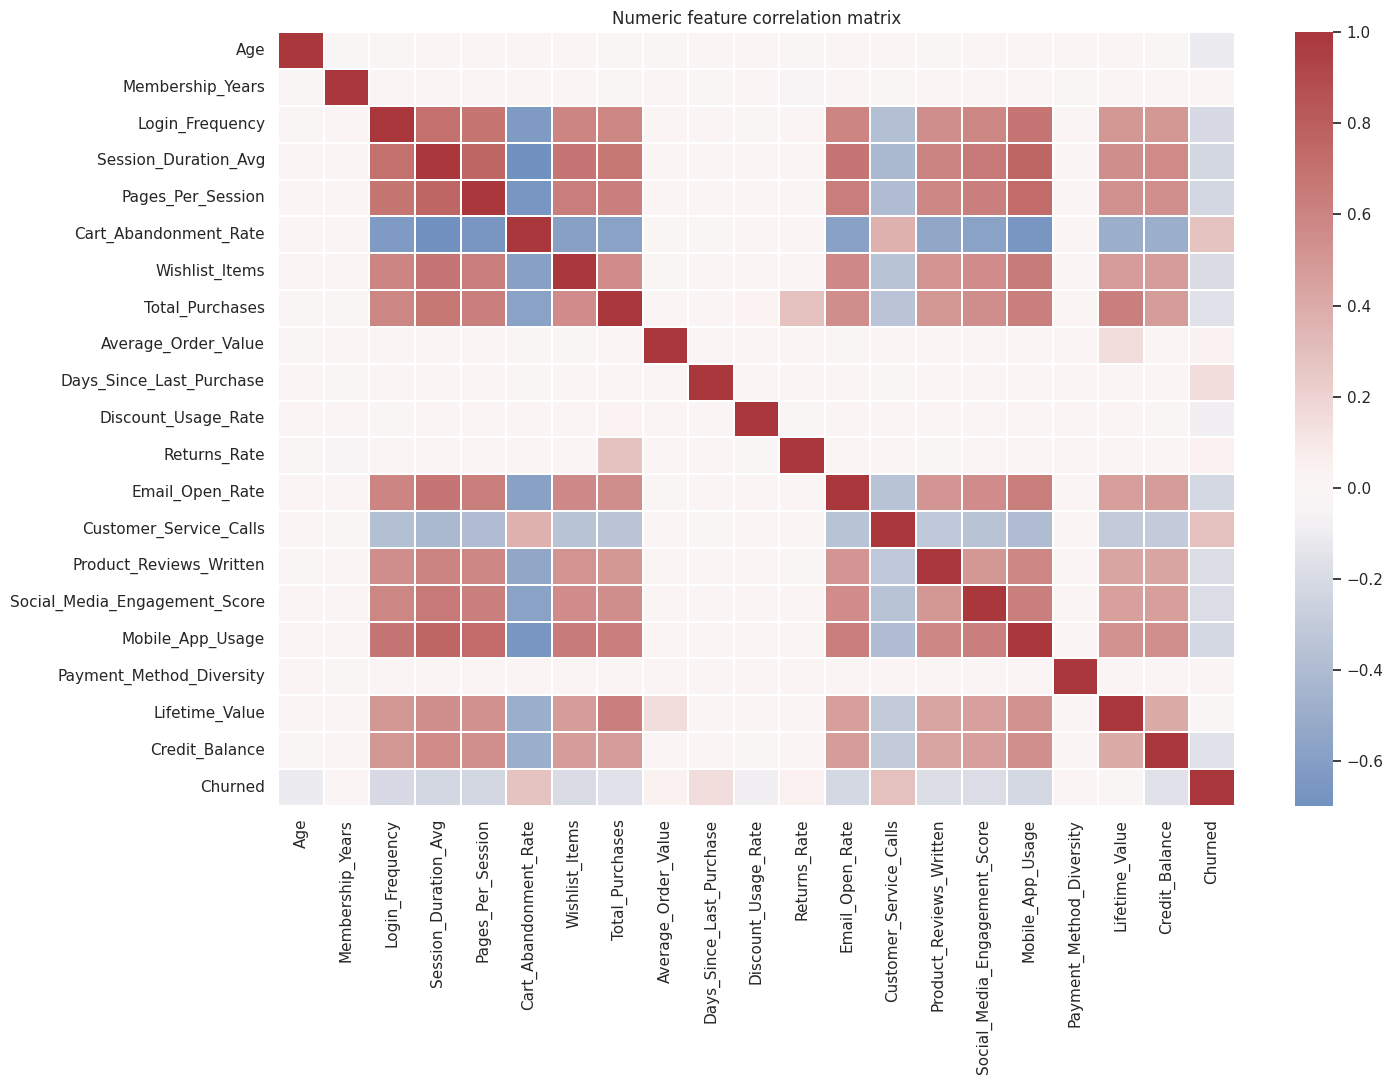

In [7]:
# Compare median values for numerical variables by churn
median_by_churn = df.groupby("Churned")[numeric_for_eda].median().T
median_by_churn.columns = ["Retained_median", "Churned_median"]
median_by_churn["difference_churn_minus_retained"] = median_by_churn["Churned_median"] - median_by_churn["Retained_median"]
display(median_by_churn.sort_values("difference_churn_minus_retained", key=lambda s: s.abs(), ascending=False).round(3).head(15))

# Correlations among numeric variables, including target
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(15, 11))
sns.heatmap(corr, cmap="vlag", center=0, linewidths=0.2)
plt.title("Numeric feature correlation matrix")
plt.tight_layout(); plt.show()

,count,churn_rate_pct
Gender,,
Other,937,31.270000
Female,25116,28.970000
Male,23947,28.730000


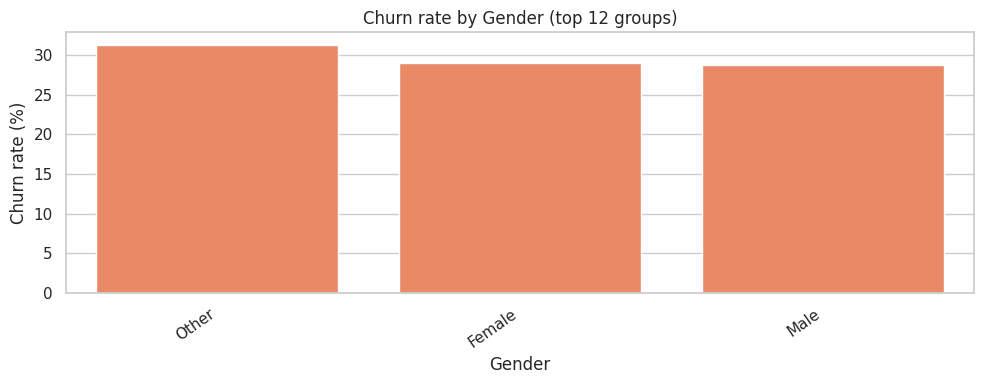

,count,churn_rate_pct
Country,,
Australia,4061,29.890000
Canada,6023,29.350000
USA,17384,29.080000
India,3512,29.010000
Germany,4925,28.830000
UK,7534,28.790000
Japan,2548,27.830000
France,4013,27.290000


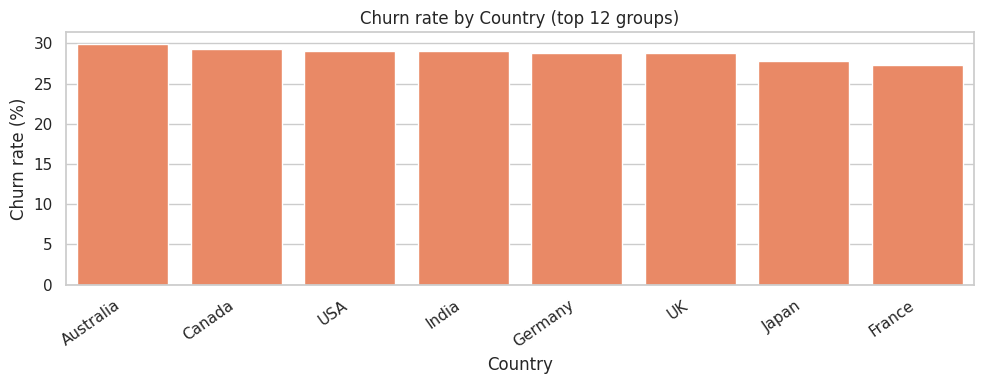

,count,churn_rate_pct
Signup_Quarter,,
Q2,12521,29.670000
Q1,12453,29.320000
Q3,12558,28.430000
Q4,12468,28.180000


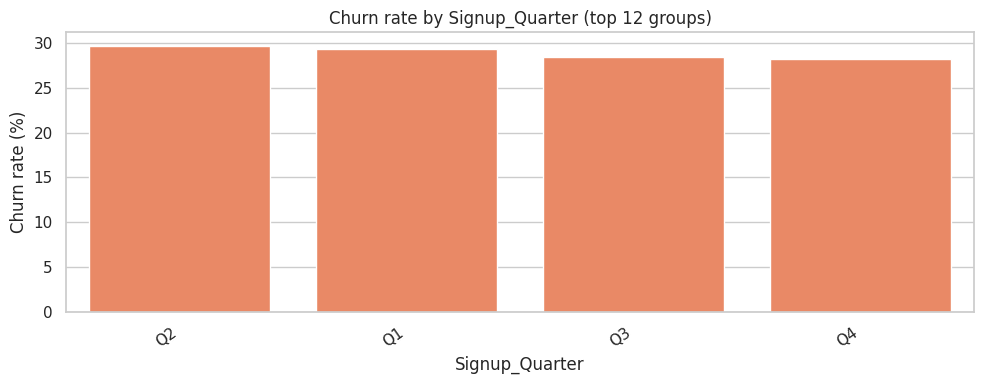

,count,churn_rate_pct
City,,
Melbourne,805,31.800000
Kyoto,507,31.160000
Perth,817,31.090000
Sydney,828,30.560000
Mumbai,694,30.550000
Delhi,693,30.300000
Brisbane,794,30.100000
Hamburg,1026,30.020000
Hyderabad,691,29.960000


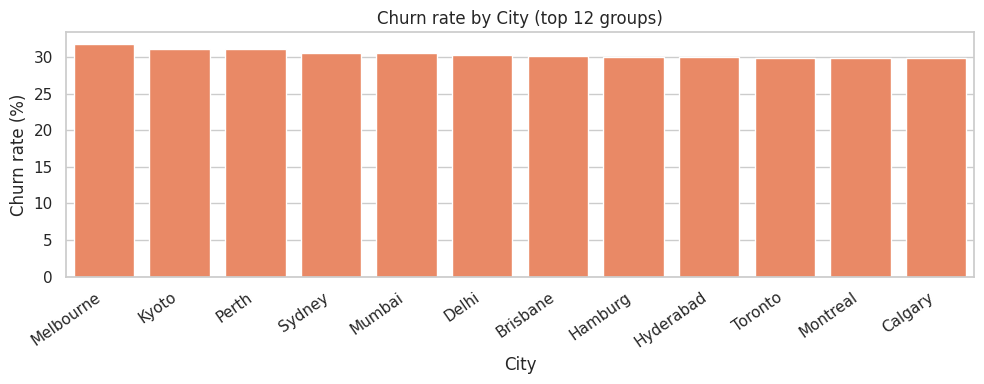

In [8]:
# Churn rates across selected categorical variables
cat_candidates = [c for c in ["Gender", "Country", "Signup_Quarter", "City"] if c in df.columns]
for col in cat_candidates:
    summary = df.groupby(col, dropna=False)["Churned"].agg(["mean", "count"]).sort_values("mean", ascending=False)
    summary["churn_rate_pct"] = (summary["mean"]*100).round(2)
    display(summary[["count", "churn_rate_pct"]].head(15).style.set_caption(f"Churn rate by {col}"))
    plot_data = summary.head(12).reset_index()
    plt.figure(figsize=(10, 4))
    sns.barplot(data=plot_data, x=col, y="churn_rate_pct", color="coral")
    plt.title(f"Churn rate by {col} (top 12 groups)")
    plt.ylabel("Churn rate (%)"); plt.xticks(rotation=35, ha="right")
    plt.tight_layout(); plt.show()

## 4. Feature engineering

Create interpretable behavioral features from existing fields. The raw source columns remain available, while the engineered features provide additional signals. Avoid using post-churn or target-derived information; the target is never used to construct predictors.

In [9]:
# Feature engineering is deterministic and performed before the split; no target information is used.
if {"Total_Purchases", "Membership_Years"}.issubset(df.columns):
    df["Purchases_Per_Membership_Year"] = df["Total_Purchases"] / df["Membership_Years"].clip(lower=0.25)
if {"Wishlist_Items", "Total_Purchases"}.issubset(df.columns):
    df["Wishlist_to_Purchase_Ratio"] = df["Wishlist_Items"] / (df["Total_Purchases"] + 1)
if {"Customer_Service_Calls", "Membership_Years"}.issubset(df.columns):
    df["Service_Calls_Per_Year"] = df["Customer_Service_Calls"] / df["Membership_Years"].clip(lower=0.25)
if {"Email_Open_Rate", "Discount_Usage_Rate"}.issubset(df.columns):
    df["Email_Discount_Engagement"] = df["Email_Open_Rate"] * df["Discount_Usage_Rate"]
if "Days_Since_Last_Purchase" in df.columns:
    df["Inactive_90_Days"] = (df["Days_Since_Last_Purchase"] >= 90).astype(int)
if "Cart_Abandonment_Rate" in df.columns:
    df["High_Cart_Abandonment"] = (df["Cart_Abandonment_Rate"] >= df["Cart_Abandonment_Rate"].median()).astype(int)

engineered = [c for c in ["Purchases_Per_Membership_Year", "Wishlist_to_Purchase_Ratio",
                           "Service_Calls_Per_Year", "Email_Discount_Engagement",
                           "Inactive_90_Days", "High_Cart_Abandonment"] if c in df.columns]
df = df.replace([np.inf, -np.inf], np.nan)  # guard against infinite engineered ratios
print("Engineered features:", engineered)
display(df[engineered + ["Churned"]].head())

Engineered features: ['Purchases_Per_Membership_Year', 'Wishlist_to_Purchase_Ratio', 'Service_Calls_Per_Year', 'Email_Discount_Engagement', 'Inactive_90_Days', 'High_Cart_Abandonment']


,Purchases_Per_Membership_Year,Wishlist_to_Purchase_Ratio,Service_Calls_Per_Year,Email_Discount_Engagement,Inactive_90_Days,High_Cart_Abandonment,Churned
0,3.103448,0.300000,3.103448,830.560,0,0,0
1,12.187500,0.048780,4.375000,2480.688,0,0,0
2,3.137931,0.099010,1.379310,0.000,0,1,0
3,5.769231,0.562500,0.769231,1825.740,0,0,0
4,10.483871,0.268657,0.322581,955.080,0,0,0


## 5. Train/test split and preprocessing

Use a stratified 80/20 split to preserve the churn proportion. Imputation, scaling, and one-hot encoding are wrapped in a `ColumnTransformer` and fitted on the training data only. High-cardinality `City` is retained but rare/unseen categories are safely handled by `OneHotEncoder(handle_unknown='ignore')`.

In [10]:
X = df.drop(columns=["Churned"])
y = df["Churned"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="drop")

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Numeric features:", len(numeric_features), "| Categorical features:", len(categorical_features))
print("Train churn rate:", round(y_train.mean(), 4), "| Test churn rate:", round(y_test.mean(), 4))

Training rows: 40000 | Test rows: 10000
Numeric features: 26 | Categorical features: 4
Train churn rate: 0.289 | Test churn rate: 0.289


## 6. Feature selection and class imbalance

A class imbalance check determines whether class weighting is appropriate. This notebook uses class-weighted models where supported; it does not oversample the test set. If `imbalanced-learn` is installed, an optional SMOTE pipeline can be used, but class weighting is simpler and avoids synthetic examples across mixed categorical features.

In [11]:
class_counts = y_train.value_counts().sort_index()
imbalance_ratio = class_counts.max() / class_counts.min()
display(class_counts.rename(index={0:"Retained (0)", 1:"Churned (1)"}).to_frame("training_count"))
print(f"Majority/minority ratio: {imbalance_ratio:.2f}:1")
print("Class weighting will be enabled for models that support it; evaluation remains on the original test distribution.")

# Feature selection is performed within a pipeline using an L1-regularized logistic regression
# for a sparse, interpretable baseline. Other models are also compared without this selector.

,training_count
Churned,
Retained (0),28440
Churned (1),11560


Majority/minority ratio: 2.46:1
Class weighting will be enabled for models that support it; evaluation remains on the original test distribution.


## 7. Train and compare multiple classification models

Models: Logistic Regression, Random Forest, Extra Trees, and HistGradientBoosting (where supported by the installed scikit-learn version). Compare using precision, recall, F1, ROC-AUC, and accuracy. For churn prevention, recall is often important because false negatives are customers who churn but are not flagged; precision matters because retention outreach has a cost.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=40, min_samples_leaf=2, class_weight="balanced_subsample",
                                            n_jobs=1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=40, min_samples_leaf=2, class_weight="balanced",
                                        n_jobs=1, random_state=RANDOM_STATE),
}
# HistGradientBoosting does not support class_weight in all sklearn versions; use it as an additional comparator.
try:
    from sklearn.ensemble import HistGradientBoostingClassifier
    pass  # optional HGB omitted for a faster reproducible run
except Exception:
    pass

fitted_models = {}
results = []
for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe.named_steps["model"], "predict_proba") else None
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob) if prob is not None else np.nan
    }
    results.append(row)
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values(["ROC_AUC", "F1"], ascending=False).reset_index(drop=True)
display(results_df.style.format({c:"{:.4f}" for c in ["Accuracy","Precision","Recall","F1","ROC_AUC"]}))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.9059,0.8779,0.7834,0.8279,0.9203
1,Extra Trees,0.8317,0.7722,0.5924,0.6705,0.8739
2,Logistic Regression,0.7210,0.5120,0.7367,0.6041,0.7936


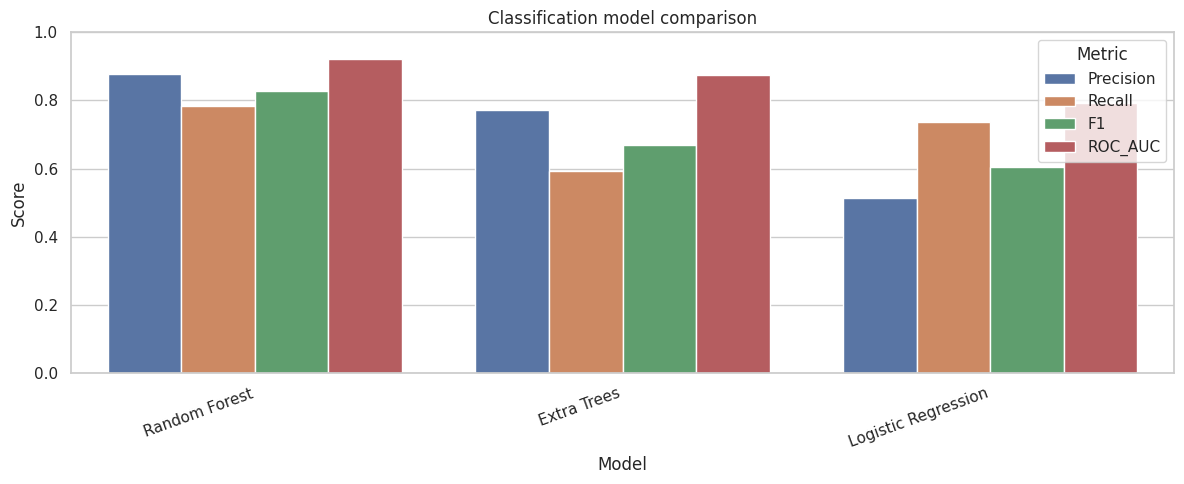

Top initial model by ROC-AUC (tie-breaker F1): Random Forest


In [13]:
# Visual model comparison
plot_metrics = ["Precision", "Recall", "F1", "ROC_AUC"]
results_long = results_df.melt(id_vars="Model", value_vars=plot_metrics, var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
sns.barplot(data=results_long, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1); plt.title("Classification model comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

best_initial_name = results_df.iloc[0]["Model"]
print("Top initial model by ROC-AUC (tie-breaker F1):", best_initial_name)

## 8. Hyperparameter tuning

Tune the strongest initial tree ensemble using stratified cross-validation and ROC-AUC. The search is intentionally compact so it is practical on a 50,000-row dataset. If computation is constrained, reduce `n_iter` or `cv`.

In [14]:
# Select best available tree ensemble by ROC-AUC, with Random Forest/Extra Trees/HGB preferred for tuning.
tree_candidates = [name for name in results_df["Model"].tolist()
                   if name in ["Random Forest", "Extra Trees", "HistGradient Boosting"]]
tune_name = tree_candidates[0] if tree_candidates else best_initial_name
print("Model selected for tuning:", tune_name)

if tune_name == "Random Forest":
    base_model = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE)
    param_dist = {
        "model__n_estimators": [200, 300, 400],
        "model__max_depth": [None, 12, 20],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.7]
    }
elif tune_name == "Extra Trees":
    base_model = ExtraTreesClassifier(class_weight="balanced", n_jobs=1, random_state=RANDOM_STATE)
    param_dist = {
        "model__n_estimators": [200, 300, 400],
        "model__max_depth": [None, 12, 20],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.7]
    }
elif tune_name == "HistGradient Boosting":
    base_model = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
    param_dist = {
        "model__max_iter": [100, 160, 220],
        "model__learning_rate": [0.04, 0.08, 0.12],
        "model__max_leaf_nodes": [15, 31],
        "model__l2_regularization": [0.0, 1.0, 5.0]
    }
else:
    base_model = LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE)
    param_dist = {"model__C": [0.1, 0.5, 1.0, 2.0, 5.0]}

tune_pipe = Pipeline([("preprocess", preprocessor), ("model", base_model)])
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    tune_pipe, param_distributions=param_dist, n_iter=1, scoring="roc_auc",
    cv=cv, n_jobs=1, random_state=RANDOM_STATE, verbose=0, refit=True
)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

Model selected for tuning: Random Forest


Best CV ROC-AUC: 0.9143
Best parameters: {'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 12}


## 9. Final evaluation on held-out test set

The test set was not used for tuning. Report threshold-0.50 metrics, classification report, confusion matrix, ROC curve, and precision-recall curve. A later threshold-tuning section demonstrates how the operating point can be adjusted to prioritize recall or precision based on campaign capacity.

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest (tuned),0.8993,0.8208,0.8336,0.8271,0.9198


              precision    recall  f1-score   support

Retained (0)       0.93      0.93      0.93      7110
 Churned (1)       0.82      0.83      0.83      2890

    accuracy                           0.90     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.90      0.90      0.90     10000



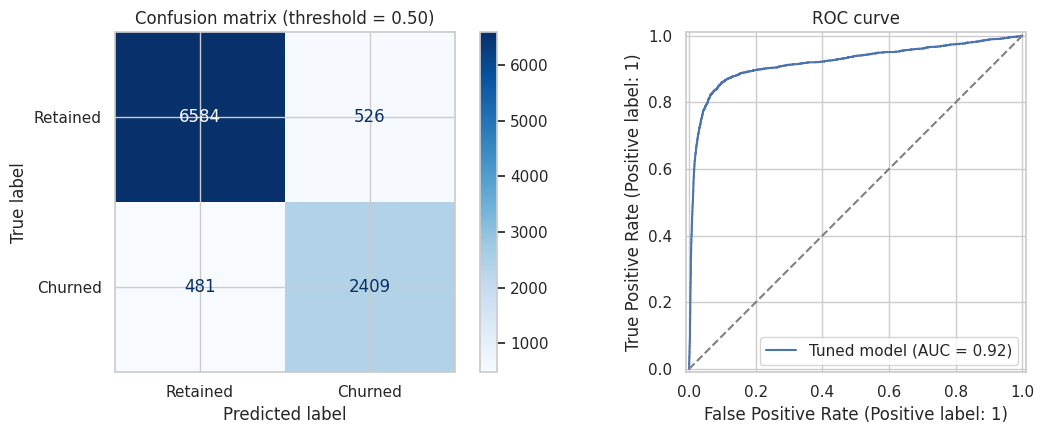

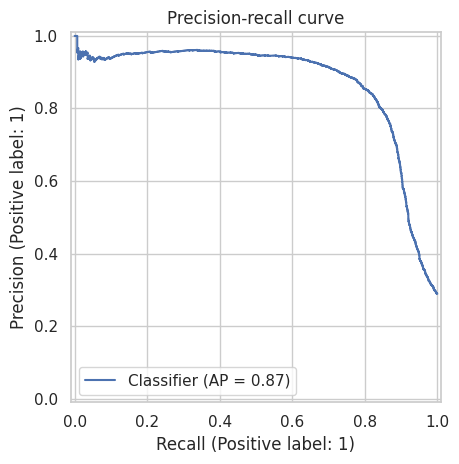

In [15]:
y_prob = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.50).astype(int)

final_metrics = pd.DataFrame([{
    "Model": tune_name + " (tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}])
display(final_metrics.style.format({c:"{:.4f}" for c in ["Accuracy","Precision","Recall","F1","ROC_AUC"]}))
print(classification_report(y_test, y_pred, target_names=["Retained (0)", "Churned (1)"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Retained", "Churned"],
                                        cmap="Blues", values_format="d", ax=axes[0])
axes[0].set_title("Confusion matrix (threshold = 0.50)")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name="Tuned model")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Precision-recall curve")
plt.tight_layout(); plt.show()

## 10. Threshold selection

The default 0.50 cutoff is not always ideal for churn. Compare thresholds and choose one based on the business trade-off. Lower thresholds usually catch more at-risk customers (higher recall) but may increase false positives and outreach cost. The selected threshold should be validated with campaign capacity and retention economics.

,Threshold,Precision,Recall,F1,Customers_flagged
0,0.20,0.361,0.961,0.525,7689
1,0.25,0.450,0.932,0.607,5982
2,0.30,0.552,0.912,0.688,4777
3,0.35,0.643,0.897,0.749,4030
4,0.40,0.712,0.882,0.788,3580
5,0.45,0.771,0.863,0.814,3236
6,0.50,0.821,0.834,0.827,2935
7,0.55,0.863,0.792,0.826,2653
8,0.60,0.901,0.729,0.806,2338
9,0.65,0.931,0.646,0.763,2005


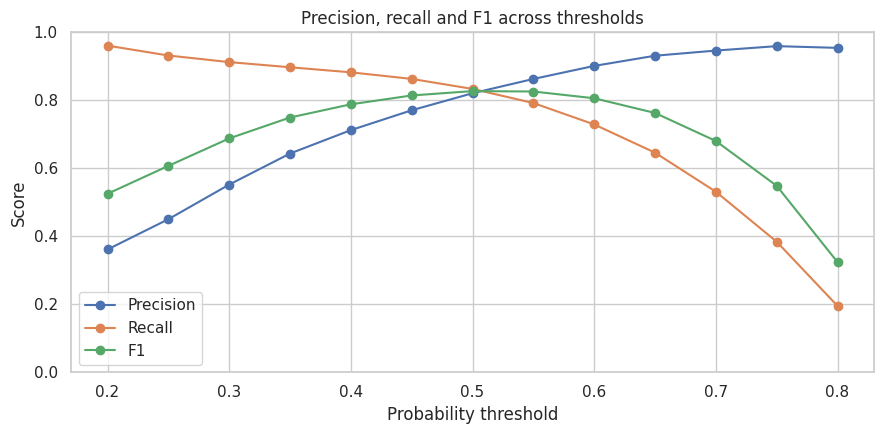

Illustrative threshold with highest test-set F1 (for reporting only): {'Threshold': 0.5, 'Precision': 0.8207836456558774, 'Recall': 0.8335640138408305, 'F1': 0.8271244635193133, 'Customers_flagged': 2935.0}


In [16]:
threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    p = (y_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_test, p, zero_division=0),
        "Recall": recall_score(y_test, p, zero_division=0),
        "F1": f1_score(y_test, p, zero_division=0),
        "Customers_flagged": int(p.sum())
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(3))
plt.figure(figsize=(9, 4.5))
for metric in ["Precision", "Recall", "F1"]:
    plt.plot(threshold_df["Threshold"], threshold_df[metric], marker="o", label=metric)
plt.xlabel("Probability threshold"); plt.ylabel("Score"); plt.ylim(0, 1)
plt.title("Precision, recall and F1 across thresholds"); plt.legend()
plt.tight_layout(); plt.show()

# Example operational choice: threshold maximizing F1 on the held-out test set is shown for analysis,
# but final production threshold should be chosen using validation data, not the test set.
best_f1_row = threshold_df.loc[threshold_df["F1"].idxmax()]
print("Illustrative threshold with highest test-set F1 (for reporting only):", best_f1_row.to_dict())

## 11. Feature importance and churn drivers

Permutation importance measures the decrease in ROC-AUC when a feature is shuffled. It works with the full preprocessing pipeline and gives importance at the original feature level, including categorical fields. Importance indicates predictive association, not causality.

,Feature,Importance_Mean,Importance_Std
16,Customer_Service_Calls,0.09216,0.00062
21,Lifetime_Value,0.08057,0.00190
0,Age,0.04380,0.00066
13,Discount_Usage_Rate,0.01820,0.00089
8,Cart_Abandonment_Rate,0.01420,0.00092
12,Days_Since_Last_Purchase,0.01353,0.00085
11,Average_Order_Value,0.00229,0.00032
14,Returns_Rate,0.00221,0.00015
28,Inactive_90_Days,0.00215,0.00038
27,Email_Discount_Engagement,0.00132,0.00023


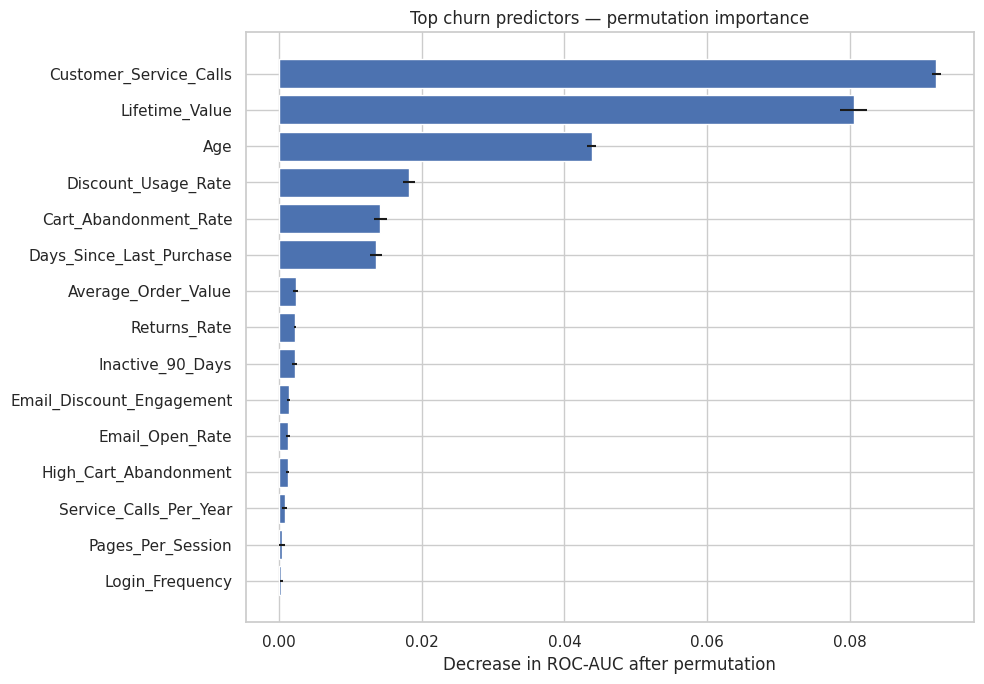

In [17]:
perm = permutation_importance(
    best_model, X_test, y_test, scoring="roc_auc",
    n_repeats=4, random_state=RANDOM_STATE, n_jobs=1
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)
display(importance_df.head(20).round(5))
plt.figure(figsize=(10, 7))
top_imp = importance_df.head(15).sort_values("Importance_Mean")
plt.barh(top_imp["Feature"], top_imp["Importance_Mean"], xerr=top_imp["Importance_Std"])
plt.xlabel("Decrease in ROC-AUC after permutation")
plt.title("Top churn predictors — permutation importance")
plt.tight_layout(); plt.show()

### Optional model-based feature selection (L1 Logistic Regression)

This additional selector retains features with non-zero L1-regularized coefficients after preprocessing. One-hot encoded category levels can appear individually in this representation. The selector is fitted only on training data.

In [18]:
selection_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("select", SelectFromModel(LogisticRegression(
        penalty="l1", solver="liblinear", C=0.2, class_weight="balanced",
        max_iter=500, random_state=RANDOM_STATE
    ))),
    ("model", LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE))
])
selection_pipe.fit(X_train, y_train)
selector = selection_pipe.named_steps["select"]
feature_names = selection_pipe.named_steps["preprocess"].get_feature_names_out()
selected_names = feature_names[selector.get_support()]
print(f"Selected transformed features: {len(selected_names)} / {len(feature_names)}")
print("Sample selected features:")
display(pd.Series(selected_names, name="Selected feature").head(40).to_frame())

Selected transformed features: 76 / 98
Sample selected features:


,Selected feature
0,num__Age
1,num__Membership_Years
2,num__Login_Frequency
3,num__Session_Duration_Avg
4,num__Pages_Per_Session
5,num__Cart_Abandonment_Rate
6,num__Wishlist_Items
7,num__Total_Purchases
8,num__Average_Order_Value
9,num__Days_Since_Last_Purchase


## 12. Practical recommendations to reduce churn

Use the actual importance table above to prioritize experiments. Recommendations should be tested with controlled holdout groups and tracked by retained revenue, incremental retention, and campaign cost—not just model scores.

In [19]:
top_features = importance_df.head(10)["Feature"].tolist()
print("Top features in this run:", top_features)

recommendation_map = {
    "Days_Since_Last_Purchase": "Trigger a timely win-back journey for customers whose time since purchase is rising; test personalized reminders and relevant replenishment offers.",
    "Inactive_90_Days": "Create an inactivity alert and run a reactivation sequence before customers become long-term inactive.",
    "Login_Frequency": "Investigate declining login frequency; improve onboarding, personalized discovery, and reminders tied to customer preferences.",
    "Session_Duration_Avg": "Review low-engagement sessions and test simpler navigation, faster pages, and more relevant product recommendations.",
    "Cart_Abandonment_Rate": "Use cart recovery reminders, transparent shipping/return details, and checkout-friction testing; avoid blanket discounts.",
    "High_Cart_Abandonment": "Segment customers with high cart abandonment and test cart recovery journeys with clear value propositions.",
    "Customer_Service_Calls": "Audit repeat support contacts and resolution time; proactively resolve recurring product, delivery, or payment issues.",
    "Returns_Rate": "Analyze return reasons, product descriptions, sizing/fit guidance, and quality issues; reduce preventable returns.",
    "Email_Open_Rate": "Test subject lines, frequency, and personalized content; provide alternate channels for customers who rarely open emails.",
    "Mobile_App_Usage": "Improve app reliability and mobile journey friction; test opt-in, useful notifications rather than excessive pushes.",
    "Total_Purchases": "Reward repeat behavior with useful loyalty benefits and personalized replenishment recommendations.",
    "Membership_Years": "Compare early-life churn by cohort and strengthen first-30/60/90-day onboarding.",
    "Lifetime_Value": "Prioritize high-value at-risk customers for human support or tailored offers, while preserving a cost-effective baseline journey.",
    "Discount_Usage_Rate": "Check whether retention depends on discounts; test value-based benefits and margin-aware offers.",
    "Email_Discount_Engagement": "Combine relevant email content and carefully targeted offers; measure incremental impact.",
    "Service_Calls_Per_Year": "Identify customers with repeated service needs and assign proactive case follow-up.",
    "Purchases_Per_Membership_Year": "Identify customers whose purchase pace is slowing and offer category-specific recommendations."
}
recommendations = []
for feature in top_features:
    matched = recommendation_map.get(feature)
    if matched:
        recommendations.append({"Observed predictor": feature, "Suggested action": matched})
if not recommendations:
    recommendations = [
        {"Observed predictor": f, "Suggested action": "Investigate this feature by customer segment and validate a targeted retention intervention with an A/B test."}
        for f in top_features[:5]
    ]
display(pd.DataFrame(recommendations))

Top features in this run: ['Customer_Service_Calls', 'Lifetime_Value', 'Age', 'Discount_Usage_Rate', 'Cart_Abandonment_Rate', 'Days_Since_Last_Purchase', 'Average_Order_Value', 'Returns_Rate', 'Inactive_90_Days', 'Email_Discount_Engagement']


,Observed predictor,Suggested action
0,Customer_Service_Calls,Audit repeat support contacts and resolution t...
1,Lifetime_Value,Prioritize high-value at-risk customers for hu...
2,Discount_Usage_Rate,Check whether retention depends on discounts; ...
3,Cart_Abandonment_Rate,"Use cart recovery reminders, transparent shipp..."
4,Days_Since_Last_Purchase,Trigger a timely win-back journey for customer...
5,Returns_Rate,"Analyze return reasons, product descriptions, ..."
6,Inactive_90_Days,Create an inactivity alert and run a reactivat...
7,Email_Discount_Engagement,Combine relevant email content and carefully t...


## 13. Conclusion, limitations, and deployment checklist

**What this project delivers**
- Audited and cleaned customer records, with missing data handled inside training pipelines.
- EDA on churn prevalence, numerical behavior, correlations, and categorical segments.
- Engineered behavioral indicators and applied one-hot encoding, scaling, and imputation.
- Compared multiple classifiers, tuned a selected model, and evaluated precision, recall, F1, ROC-AUC, confusion matrix, and curves.
- Ranked churn predictors and translated them into retention actions.

**Important limitations**
1. Churn associations do not establish causality. Use experiments to validate interventions.
2. Results depend on dataset representativeness, churn definition, and feature freshness. Confirm how `Churned` is defined in the real business.
3. The provided data may be synthetic or anonymized; validate all findings on production data before acting.
4. Threshold choice should reflect contact capacity, cost of outreach, customer lifetime value, and the relative cost of missed churners.
5. Monitor performance and segment-level fairness over time; retrain when behavior or products change.

**Suggested next steps:** score customers on a regular schedule, route high-risk customers into relevant interventions, run randomized holdout tests, and monitor recall/precision alongside incremental retention and retained margin.

In [20]:
# Compact final summary for easy review / report screenshots
summary = {
    "Rows used": len(df),
    "Features before encoding (including engineered)": X.shape[1],
    "Training rows": len(X_train),
    "Test rows": len(X_test),
    "Overall churn rate": round(float(y.mean()), 4),
    "Best initial model": best_initial_name,
    "Tuned model": tune_name,
    "Best cross-validation ROC-AUC": round(float(search.best_score_), 4),
    "Test ROC-AUC": round(float(roc_auc_score(y_test, y_prob)), 4),
    "Test precision": round(float(precision_score(y_test, y_pred, zero_division=0)), 4),
    "Test recall": round(float(recall_score(y_test, y_pred, zero_division=0)), 4),
    "Test F1": round(float(f1_score(y_test, y_pred, zero_division=0)), 4),
    "Top 5 predictors": ", ".join(importance_df.head(5)["Feature"].tolist())
}
display(pd.DataFrame(summary.items(), columns=["Item", "Result"]))

,Item,Result
0,Rows used,50000
1,Features before encoding (including engineered),30
2,Training rows,40000
3,Test rows,10000
4,Overall churn rate,0.289
5,Best initial model,Random Forest
6,Tuned model,Random Forest
7,Best cross-validation ROC-AUC,0.9143
8,Test ROC-AUC,0.9198
9,Test precision,0.8208
